# ShoreSense - Module 1: Species Detection (YOLOv8)

## Imports

In [1]:
import os
import glob
import shutil
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO

## Dataset Path

In [2]:
DATA_DIR = r"D:\GUVI\Shore_sense\data\yolo"
DATA_YAML = DATA_DIR + "/data.yaml"

## Check data.yaml

In [3]:
with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)

names = cfg["names"]
class_names = list(names.values()) if isinstance(names, dict) else names
print(len(class_names), class_names)

6 ['bottlenose_dolphin', 'green_turtle', 'hammerhead_shark', 'hawaiian_monk_seal', 'north_atlantic_right_whale', 'whale_shark']


## Count Images and Labels per Split

In [4]:
for split in ["train", "valid", "test"]:
    n_img = len(glob.glob(f"{DATA_DIR}/{split}/images/*"))
    n_lbl = len(glob.glob(f"{DATA_DIR}/{split}/labels/*.txt"))
    print(split, "images:", n_img, "labels:", n_lbl)

train images: 1967 labels: 1967
valid images: 0 labels: 0
test images: 353 labels: 353


## Class Balance

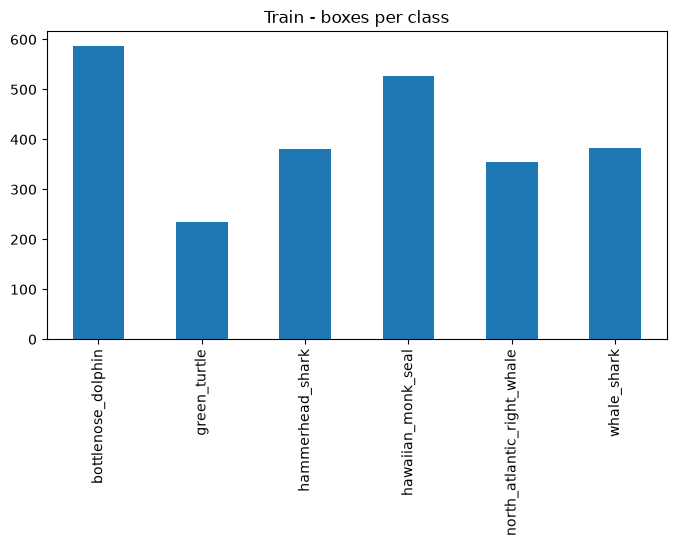

In [5]:
counts = {name: 0 for name in class_names}

for file in glob.glob(f"{DATA_DIR}/train/labels/*.txt"):
    for line in open(file):
        class_id = int(line.split()[0])
        counts[class_names[class_id]] += 1

pd.Series(counts).plot(kind="bar", figsize=(8, 4))
plt.title("Train - boxes per class")
plt.show()

## Sample Images with Boxes

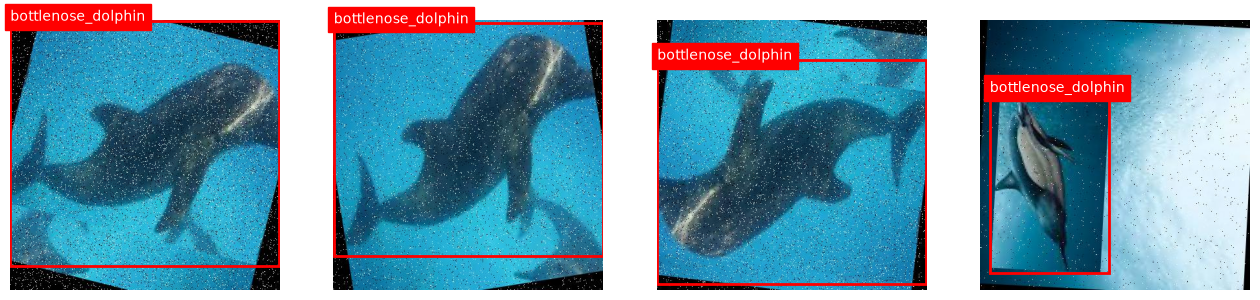

In [6]:
sample_images = glob.glob(f"{DATA_DIR}/train/images/*")[:4]

plt.figure(figsize=(16, 4))
for i, path in enumerate(sample_images):
    img = Image.open(path)
    w, h = img.size
    ax = plt.subplot(1, 4, i + 1)
    ax.imshow(img)
    ax.axis("off")

    label_path = path.replace("images", "labels").rsplit(".", 1)[0] + ".txt"
    for line in open(label_path):
        c, x, y, bw, bh = map(float, line.split()[:5])
        x1 = (x - bw / 2) * w
        y1 = (y - bh / 2) * h
        ax.add_patch(patches.Rectangle((x1, y1), bw * w, bh * h, fill=False, color="red", linewidth=2))
        ax.text(x1, y1, class_names[int(c)], color="white", backgroundcolor="red")
plt.show()

## Train YOLOv8n

In [2]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
NVIDIA RTX PRO 500 Blackwell Generation Laptop GPU


In [ ]:
model = YOLO("yolov8n.pt")
results = model.train(data=DATA_YAML, epochs=30, imgsz=640, batch=8, device=0, name="shoresense")
save_dir = str(results.save_dir)
print(save_dir)

Ultralytics 8.4.218  Python-3.12.0 torch-2.14.1+cu132 CUDA:0 (NVIDIA RTX PRO 500 Blackwell Generation Laptop GPU, 6113MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=shoresense, nbs=64, nms=None,

## Training Curves

In [ ]:
plt.figure(figsize=(14, 8))
plt.imshow(Image.open(save_dir + "/results.png"))
plt.axis("off")
plt.show()

## Save best.pt

In [ ]:
os.makedirs("models", exist_ok=True)
shutil.copy(save_dir + "/weights/best.pt", "models/best.pt")

## Validation Results

In [ ]:
best_model = YOLO("models/best.pt")
val = best_model.val(data=DATA_YAML, split="val")

print("Precision:", val.box.mp)
print("Recall:", val.box.mr)
print("mAP50:", val.box.map50)
print("mAP50-95:", val.box.map)

## Per-Class mAP50

In [ ]:
table = pd.DataFrame({
    "class": [class_names[i] for i in val.box.ap_class_index],
    "mAP50": val.box.ap50
})
table

## Confusion Matrix

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(Image.open(str(val.save_dir) + "/confusion_matrix.png"))
plt.axis("off")
plt.show()

## Test Results (Run Once)

In [ ]:
test = best_model.val(data=DATA_YAML, split="test")

print("Precision:", test.box.mp)
print("Recall:", test.box.mr)
print("mAP50:", test.box.map50)
print("mAP50-95:", test.box.map)

## Detect Species Function

In [ ]:
def detect_species(image_path):
    result = best_model.predict(image_path, conf=0.25)[0]

    if len(result.boxes) == 0:
        return None

    i = int(result.boxes.conf.argmax())
    species = best_model.names[int(result.boxes.cls[i])]
    confidence = float(result.boxes.conf[i])
    box = result.boxes.xyxy[i].tolist()
    return species, confidence, box

## Try the Function

In [ ]:
test_images = glob.glob(f"{DATA_DIR}/test/images/*")
print(detect_species(test_images[0]))